# Part 1 Aggregation 

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.stats import entropy
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.feature_selection import mutual_info_classif, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
import time
df = pd.read_csv("Telco_Customer_Churn.csv")

df.shape

(7043, 21)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

the column TotalCharges defined as string, because there is some empty rows in brackets " "

In [3]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


So i defined dataframe as df function (via pandas library) and imported dataset from kaggle, then i used df.head command in order to check does the jupiter see and can manipulate with dataset also i inspected dataset by df.info() function

In [4]:
#1a
pivot = pd.pivot_table(
    df, index = "Contract", columns = "InternetService", 
    values = "MonthlyCharges", aggfunc = ["mean", "median", "std", "count"]

)

display(pivot)

mean                        median                     \
InternetService        DSL Fiber optic         No    DSL Fiber optic     No   
Contract                                                                      
Month-to-month   50.219501   87.021194  20.409542  50.20       86.00  20.05   
One year         61.396754   98.779499  20.819505  61.05      100.15  20.10   
Two year         70.462978  104.571445  21.777351  73.30      106.30  20.35   

                       std                       count                   
InternetService        DSL Fiber optic        No   DSL Fiber optic   No  
Contract                                                                 
Month-to-month   13.029810   11.198021  1.524728  1223        2128  524  
One year         13.966867    9.349157  1.962743   570         539  364  
Two year         15.111798    9.422629  2.492721   628         429  638

In [5]:
#1b
group_counts = (
    df.groupby(["Contract", "InternetService"]).size().reset_index(name = "count")

    
)

group_counts["less thann 30"] = group_counts["count"] < 30

display(group_counts)

,Contract,InternetService,count,less thann 30
0,Month-to-month,DSL,1223,False
1,Month-to-month,Fiber optic,2128,False
2,Month-to-month,No,524,False
3,One year,DSL,570,False
4,One year,Fiber optic,539,False
5,One year,No,364,False
6,Two year,DSL,628,False
7,Two year,Fiber optic,429,False
8,Two year,No,638,False


In [6]:
weighted_results = []
for contract, group in df.groupby("Contract"):
    unweighted_mean = group["MonthlyCharges"].mean()
    weighted_mean = (group["MonthlyCharges"] * group["tenure"].sum() / group["tenure"].sum())

    divergence = abs(weighted_mean - unweighted_mean )
    weighted_results.append([contract, unweighted_mean, weighted_mean, divergence])

    weighted_df = pd.DataFrame(weighted_results, columns = ["Contract", "Unweighted Mean", "Wighted MEan", "Divergence"])
    display(weighted_df)


,Contract,Unweighted Mean,Wighted MEan,Divergence
0,Month-to-month,66.39849,0 29.85 2 53.85 4 70.70 5...,0 36.54849 2 12.54849 4 4.3...


,Contract,Unweighted Mean,Wighted MEan,Divergence
0,Month-to-month,66.398490,0 29.85 2 53.85 4 70.70 5...,0 36.54849 2 12.54849 4 4.3...
1,One year,65.048608,1 56.95 3 42.30 9 56.15 1...,1 8.098608 3 22.748608 9 8...


,Contract,Unweighted Mean,Wighted MEan,Divergence
0,Month-to-month,66.398490,0 29.85 2 53.85 4 70.70 5...,0 36.54849 2 12.54849 4 4.3...
1,One year,65.048608,1 56.95 3 42.30 9 56.15 1...,1 8.098608 3 22.748608 9 8...
2,Two year,60.770413,11 18.95 15 113.25 17 106.70 2...,11 41.820413 15 52.479587 17 45...


2b The month-to-month group has the largest divergence between unweighted and weighted mean. The weighted mean is higher because customers with longer tenure have higher monthly charges so they have a stronger influence when terure is used like weight

Raw CV:  0.46462725037621877
Contract + payment method  0.21999707935517157
Contract CV:  0.045858431715923326


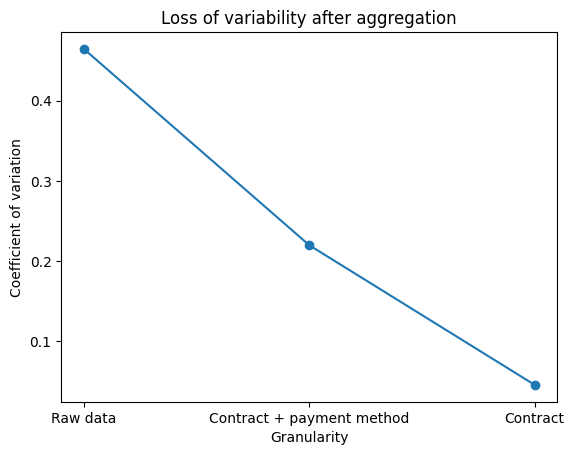

In [7]:
#lvl 1 granularity - raww data 

level1_cv = df["MonthlyCharges"].std() / df["MonthlyCharges"].mean()

# lvl 2 granularity aggregate bu contract + payment method 

level2 = df.groupby(["Contract", "PaymentMethod"])["MonthlyCharges"].mean()
level2_cv = level2.std() / level2.mean()

# lvl 3 aggregate by contract

level3 = df.groupby("Contract")["MonthlyCharges"].mean()
level3_cv = level3.std() / level3.mean()

cv_values = [level1_cv, level2_cv, level3_cv]
levels = ["Raw data", "Contract + payment method", "Contract"]

print("Raw CV: ", level1_cv)
print("Contract + payment method ",level2_cv )
print("Contract CV: ", level3_cv)

plt.plot(levels, cv_values, marker="o")
plt.xlabel("Granularity")
plt.ylabel("Coefficient of variation")
plt.title("Loss of variability after aggregation")
plt.show()

3b CV went down from 0.465 raw data to the 0.220 after grouping by contract and payment method. it dropped even more to 0.046 after grouping only by contract. this means that aggregation hides differences between individual customers, especially at the contract level

# Part 2, Sampling 

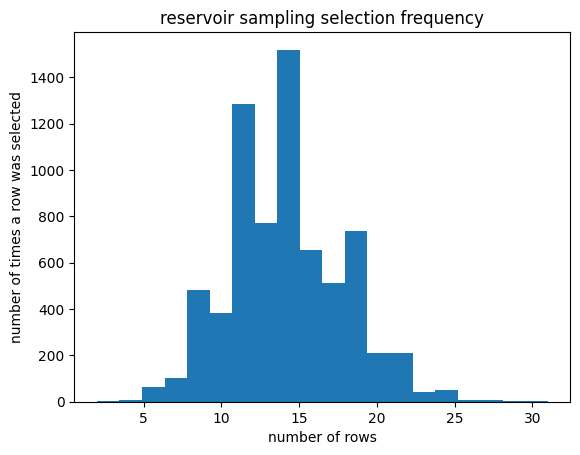

mean selection count:  14.198494959534289
min selection counts:  2
max selection counts:  31


In [8]:
#1
def reservoir_sample(stream, k = 500, seed = None):
    rng = np.random.default_rng(seed)
    reservoir = []
    for i, item in enumerate(stream):
        if i < k:
            reservoir.append(item)
        else:
            j = rng.integers(0, i+1)
            if j < k: 
                reservoir[j] = item

    return reservoir

stream = list(range(len(df)))

selection_counts = np.zeros(len(df), dtype = int)

for i in range(200):
    sample_indices = reservoir_sample(stream,500,seed = i)
    for idx in sample_indices:
        selection_counts[idx] +=1


plt.hist(selection_counts, bins=20)
plt.ylabel("number of times a row was selected")
plt.xlabel("number of rows")
plt.title("reservoir sampling selection frequency")
plt.show()

print("mean selection count: ", selection_counts.mean())
print("min selection counts: ", selection_counts.min())
print("max selection counts: ", selection_counts.max())





    

The mean selection count is about ~14.2 which is close to the expected value. the minimum was 2 and the maximum is 31, but most of the rows were selected around pretty much around the average frequency. this means that reservoir sampling gives each row approximately the same chance of being selected

In [9]:
#2a

sample_size = int(len(df) * 0.10)

full_dist = df["Churn"].value_counts(normalize=True).sort_index()
random_sample = df.sample(n=sample_size, random_state=42)

random_dist = (random_sample["Churn"].value_counts(normalize=True).sort_index())
stratified_sample,_=train_test_split(df,train_size=sample_size, stratify=df["Churn"], random_state=42)
stratified_dist = (stratified_sample["Churn"].value_counts(normalize=True).sort_index())

biased_sample = (df.sort_values("MonthlyCharges", ascending=False).head(sample_size))
biased_dist = (biased_sample["Churn"].value_counts(normalize=True).sort_index())

#Kl divergence
random_kl = entropy(random_dist, full_dist)
stratified_kl = entropy(stratified_dist, full_dist)
biased_kl = entropy(biased_dist, full_dist)

results = pd.DataFrame({"Sampling method":["Simple random", "Stratified", "Biased convenience"],"KL Divergence":[random_kl, stratified_kl, biased_kl]})
display(results)


,Sampling method,KL Divergence
0,Simple random,2.646177e-04
1,Stratified,1.669095e-07
2,Biased convenience,8.635261e-04


2b The stratified sampling gives the result closest to the full dataset because its KL divergence is almost zero. the biased sample has the biggest KL divergence, so it changes the class balance the most. this can be bad for a classifier because it may learn from an unrepresentative sample

In [10]:
#3 
sample_sizes = [100, 250, 500, 1000, 2500, 5000]

full_mean = df["MonthlyCharges"].mean()
thresold = 0.05 * full_mean

results = []

for n in sample_sizes:
    #stratified sample
    sample, _ =train_test_split(df, train_size=n, stratify=df["Churn"], random_state = 42)

    values = sample["MonthlyCharges"].values

    bootstrap_means = []
    rng = np.random.default_rng(42)

    for i in range(1000):
        bootstrap_sample = rng.choice(values, size=len(values), replace=True)
        bootstrap_means.append(bootstrap_sample.mean())

     #95% confidence interval
    lower = np.percentile(bootstrap_means, 2.5)
    upper = np.percentile(bootstrap_means, 97.5)
    ci_width = upper - lower

    results.append([n, values.mean(), lower, upper, ci_width])

results_df = pd.DataFrame(results, columns = ["Sample size", "MEan", "CI lower", "CI upper", "CI width"])
display(results_df)


,Sample size,MEan,CI lower,CI upper,CI width
0,100,61.64200,55.355038,67.548650,12.193612
1,250,63.23260,59.370180,66.885605,7.515425
2,500,63.79110,61.237223,66.338687,5.101465
3,1000,63.34560,61.610686,65.182600,3.571914
4,2500,64.58762,63.353702,65.788934,2.435232
5,5000,64.85338,63.966192,65.637868,1.671677


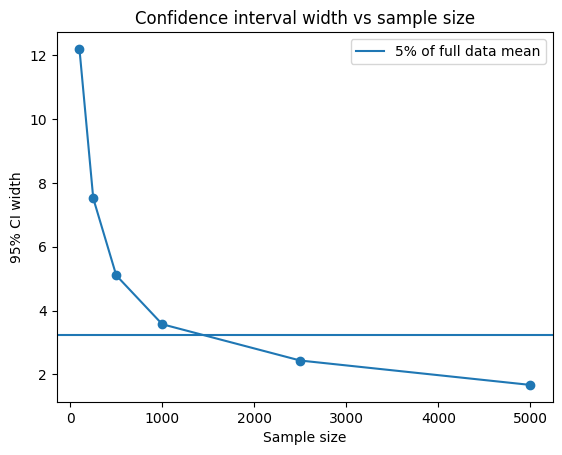

In [11]:
#making a graph
plt.plot(results_df["Sample size"], results_df["CI width"], marker="o")
plt.axhline(y=thresold, linestyle="-", label="5% of full data mean")

plt.xlabel("Sample size")
plt.ylabel("95% CI width")
plt.title("Confidence interval width vs sample size")
plt.legend()
plt.show()

In [12]:
#finding the smallest n where interval is less 5% from mean
full_mean = df["MonthlyCharges"].mean()
threshold = 0.05 * full_mean
adequate = results_df[
    results_df["CI width"] < threshold
]

if len(adequate) > 0:
    smallest_n = adequate.iloc[0]["Sample size"]
    print("Smallest adequate sample size:", int(smallest_n))
else:
    print("None of the tested sample sizes meet the condition")

print("Full data mean:", full_mean)
print("5% threshold:", threshold)

Smallest adequate sample size: 2500
Full data mean: 64.76169246059918
5% threshold: 3.238084623029959


the full data mean is about 64.76 so 5% of its about 3.24. the smallest sample size where the confidence interval width become lower than this value is 2500. this means that a stratified sample of 2500 rows in enough to estimate the ean of monthly charges with the required precision 

# Part 3 Feature Subset Selection

In [13]:
# convert total charges to numeric 
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
X = df.select_dtypes(include=np.number).dropna() # selecting only features only

removed_features = []

while True:
    vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])],index=X.columns)
    print(vif)
    print()

    max_vif = vif.max()

    if max_vif < 10:
        break

    feature_to_remove = vif.idmax()
    removed_features.append(feature_to_remove)
    X = X.drop(columns=feature_to_remove)


print("Removed features:", removed_features)
print("Number of removed features:", len(removed_features))
print("\nFinal VIF:")
print(vif)


SeniorCitizen     1.054455
tenure            5.847215
MonthlyCharges    3.314481
TotalCharges      9.543891
dtype: float64

Removed features: []
Number of removed features: 0

Final VIF:
SeniorCitizen     1.054455
tenure            5.847215
MonthlyCharges    3.314481
TotalCharges      9.543891
dtype: float64


all the numeric features have VIF values below 10 so no features needed to be removed. Total charges has the hoghest VIF at about 9.54 but its still below thresold

In [16]:
#prepearing data
data = df.copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
data["TotalCharges"] = data["TotalCharges"].fillna(data["TotalCharges"].median())

y = data["Churn"].map({"No": 0, "Yes": 1})
X = data.drop(columns=["Churn", "customerID"])

#converting categoridcal features to numeric
X = pd.get_dummies(X, drop_first=True)
#scaling features
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns = X.columns)

In [ ]:
#a
mi_scores = mutual_info_classif(X_scaled,y,random_state=42)
mi_scores = pd.Series(mi_scores,index=X_scaled.columns).sort_values(ascending=False)
mi_top6 = list(mi_scores.head(6).index)

print("Mutual Information top 6:")
print(mi_top6)

Mutual Information top 6:
['tenure', 'Contract_Two year', 'InternetService_Fiber optic', 'MonthlyCharges', 'OnlineSecurity_No internet service', 'PaymentMethod_Electronic check']


In [23]:
#b
model = LogisticRegression(max_iter=2000,random_state=42)
rfecv = RFECV(estimator=model,step=1,cv=5,scoring="f1",min_features_to_select=6,n_jobs=-1)

rfecv.fit(X_scaled, y)

selected_by_rfecv = X_scaled.columns[rfecv.support_]

#if RFECV selected more than 6 choose the 6 strongest
if len(selected_by_rfecv) > 6:
    coefficients = np.abs(rfecv.estimator_.coef_[0])

    wrapper_scores = pd.Series(coefficients,index=selected_by_rfecv).sort_values(ascending=False)
    rfecv_top6 = list(wrapper_scores.head(6).index)
else:
    rfecv_top6 = list(selected_by_rfecv)

print("RFECV top 6:")
print(rfecv_top6)

RFECV top 6:
['tenure', 'TotalCharges', 'Contract_Two year', 'InternetService_Fiber optic', 'MonthlyCharges', 'Contract_One year']


In [24]:
rf = RandomForestClassifier(n_estimators=200,random_state=42)
rf.fit(X_scaled, y)

importance = pd.Series(rf.feature_importances_,index=X_scaled.columns).sort_values(ascending=False)
embedded_top6 = list(importance.head(6).index)
print("Random Forest top 6:")
print(embedded_top6)

Random Forest top 6:
['TotalCharges', 'MonthlyCharges', 'tenure', 'InternetService_Fiber optic', 'PaymentMethod_Electronic check', 'Contract_Two year']


In [25]:

all_selected = sorted(set(mi_top6 + rfecv_top6 + embedded_top6))
comparison = pd.DataFrame(index=all_selected)
comparison["Mutual information"] = ["ok" if feature in mi_top6 else ""for feature in all_selected]
comparison["RFECV"] = ["ok" if feature in rfecv_top6 else ""for feature in all_selected]
comparison["Embedded"] = ["ok" if feature in embedded_top6 else ""for feature in all_selected]

display(comparison)

,Mutual information,RFECV,Embedded
Contract_One year,,ok,
Contract_Two year,ok,ok,ok
InternetService_Fiber optic,ok,ok,ok
MonthlyCharges,ok,ok,ok
OnlineSecurity_No internet service,ok,,
PaymentMethod_Electronic check,ok,,ok
TotalCharges,,ok,ok
tenure,ok,ok,ok


In [ ]:
#пункт b
all_three = [
    feature for feature in all_selected
    if feature in mi_top6
    and feature in rfecv_top6
    and feature in embedded_top6
]

only_one = [
    feature for feature in all_selected
    if sum([
        feature in mi_top6,
        feature in rfecv_top6,
        feature in embedded_top6
    ]) == 1
]

print("Selected by all three methods:")
print(all_three)
print("\nSelected by only one method:")
print(only_one)

Selected by all three methods:
['Contract_Two year', 'InternetService_Fiber optic', 'MonthlyCharges', 'tenure']

Selected by only one method:
['Contract_One year', 'OnlineSecurity_No internet service']


4 features were selected by all 3 methods (contract_two_year, int service fiber optic, monthlycharges, tenure). this means these features are consistently important for predicting churn. contract one year and online sec_no int service were selected by only one method. this difference is expected because each feature selection method uses a different way to measure importance

In [28]:
# 3
model = LogisticRegression(max_iter=2000)

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
#all original features
X_all = X_scaled

#VIF reduced features
X_vif = X_scaled.drop(columns=removed_features, errors="ignore")
#wrapper selected features
X_wrapper = X_scaled[rfecv_top6]

feature_sets = {"All features": X_all,"VIF reduced": X_vif,"Wrapper selected": X_wrapper}
results = []
for name, X_set in feature_sets.items():

    start = time.perf_counter()

    scores = cross_val_score(model,X_set,y,cv=cv,scoring="f1")
    end = time.perf_counter()
    results.append([name,X_set.shape[1],scores.mean(),end - start])

results_df = pd.DataFrame(results,columns=["Feature set","Number of features","Mean F1","Training time"])
display(results_df)

,Feature set,Number of features,Mean F1,Training time
0,All features,30,0.598542,0.173078
1,VIF reduced,30,0.598542,0.139438
2,Wrapper selected,6,0.553320,0.073237


all features and vif reduced gave the same F1 score of 0.599 because no features were removed by vif

# Part 4 Feature Creation

In [29]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["AvgChargePerMonth"] = np.where(df["tenure"] > 0,df["TotalCharges"] / df["tenure"],0)

service_columns = ["PhoneService","MultipleLines","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
df["ActiveServices"] = df[service_columns].apply(lambda row: sum(value == "Yes" for value in row),axis=1)
df["SecuritySupportBundle"] = ((df["OnlineSecurity"] == "Yes") &(df["TechSupport"] == "Yes")).astype(int)
df[["AvgChargePerMonth", "ActiveServices", "SecuritySupportBundle"]].head()

,AvgChargePerMonth,ActiveServices,SecuritySupportBundle
0,29.850000,1,0
1,55.573529,3,0
2,54.075000,3,0
3,40.905556,3,1
4,75.825000,1,0


new features were created successfully. angChargePerMonth shows the average monthly amount paid by each customer, ActiveServie shows how many services the customer uses, and SecuritySupportBundle shows whether the customer has both online security and tech support. these features combine information from multiple original columns and can describe customer behaviour more clearly

In [30]:
# Create a periodic feature from tenure
df["TenureMonthCycle"] = df["tenure"] % 12
# Cyclical encoding
df["TenureMonth_sin"] = np.sin(2 * np.pi * df["TenureMonthCycle"] / 12)
df["TenureMonth_cos"] = np.cos(2 * np.pi * df["TenureMonthCycle"] / 12)
display(df[["tenure", "TenureMonthCycle", "TenureMonth_sin", "TenureMonth_cos"]].head(15))

,tenure,TenureMonthCycle,TenureMonth_sin,TenureMonth_cos
0,1,1,0.500000,8.660254e-01
1,34,10,-0.866025,5.000000e-01
2,2,2,0.866025,5.000000e-01
3,45,9,-1.000000,-1.836970e-16
4,2,2,0.866025,5.000000e-01
5,8,8,-0.866025,-5.000000e-01
6,22,10,-0.866025,5.000000e-01
7,10,10,-0.866025,5.000000e-01
8,28,4,0.866025,-5.000000e-01
9,62,2,0.866025,5.000000e-01


the dataset has no date feature so a 12-month cycle was created from tenure. Sinus and cosinus encoding represent this cycle without treating the beginning and end of the cycle as far apart

In [32]:
numeric_features = df.select_dtypes(include=np.number).copy()
numeric_features = numeric_features.fillna(numeric_features.median())

y = df["Churn"].map({"No": 0, "Yes": 1})
scaler = StandardScaler()
X_numeric_scaled = scaler.fit_transform(numeric_features)
pca = PCA()
X_pca_all = pca.fit_transform(X_numeric_scaled)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1
print("Components needed for 90% variance:", n_components_90)

Components needed for 90% variance: 3


In [33]:
# the varianced ratio table 
variance_table = pd.DataFrame({
    "Component": range(1, len(pca.explained_variance_ratio_) + 1),
    "Explained Variance Ratio": pca.explained_variance_ratio_,
    "Cumulative Variance": cumulative_variance
})

display(variance_table)

,Component,Explained Variance Ratio,Cumulative Variance
0,1,0.44663,0.44663
1,2,0.32785,0.77448
2,3,0.22552,1.00000


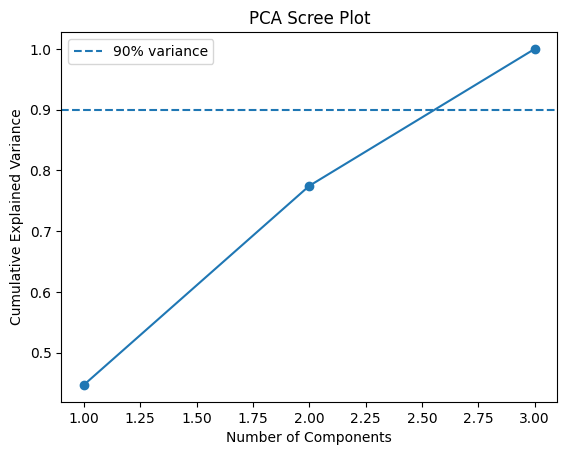

In [34]:
#scree plot 
plt.plot(variance_table["Component"],variance_table["Cumulative Variance"],marker="o")
plt.axhline(y=0.90,linestyle="--",label="90% variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Scree Plot")
plt.legend()
plt.show()

In [35]:
#leave only needed amount of PCA components
pca_90 = PCA(n_components=n_components_90)
X_pca = pca_90.fit_transform(X_numeric_scaled)

In [36]:
model = LogisticRegression(max_iter=2000)

#original numeric features
start = time.perf_counter()
original_scores = cross_val_score(model,X_numeric_scaled,y,cv=5,scoring="f1")
original_time = time.perf_counter() - start

#pca features
start = time.perf_counter()

pca_scores = cross_val_score(
    model,
    X_pca,
    y,
    cv=5,
    scoring="f1"
)


pca_time = time.perf_counter() - start
comparison = pd.DataFrame({
    "Features": ["Original Numeric", "PCA"],
    "Number of Features": [X_numeric_scaled.shape[1],n_components_90],
    "Mean F1": [original_scores.mean(),pca_scores.mean()],"Training Time": [original_time,pca_time]})

display(comparison)



,Features,Number of Features,Mean F1,Training Time
0,Original Numeric,3,0.536513,0.058049
1,PCA,3,0.536513,0.039221


PCA needed 3 components to keep 90% of the information. Both versions gave the same F1 score of 0.536. PCA was a little faster but it didnt improve the model result

In [37]:
print(numeric_features.columns)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='str')


#b
One problem with PCA is that the new features are hard to explain. ActiveServices and AvgChargePerMonth have a clear meaning but PCA components are just mixed combinations of different features 

In [39]:
# creating new features
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = X.copy()
        # average monthly charge for each group
        self.group_means = X.groupby(
            ["Contract", "InternetService"]
        )["MonthlyCharges"].mean()
        self.global_mean = X["MonthlyCharges"].mean()
        return self
    def transform(self, X):
        X = X.copy()
        X["TotalCharges"] = pd.to_numeric(X["TotalCharges"],errors="coerce")
        # aggregation feature
        X["GroupAvgMonthlyCharges"] = [self.group_means.get((contract, internet),self.global_mean)
            for contract, internet in zip(X["Contract"],X["InternetService"])]
        # average charge per month
        X["AvgChargePerMonth"] = np.where(X["tenure"] > 0,X["TotalCharges"] / X["tenure"],0)

        service_columns = [
            "PhoneService",
            "MultipleLines",
            "OnlineSecurity",
            "OnlineBackup",
            "DeviceProtection",
            "TechSupport",
            "StreamingTV",
            "StreamingMovies"
        ]

        # number of active services
        X["ActiveServices"] = X[service_columns].apply(lambda row: sum(value == "Yes" for value in row),axis=1)
        # customer has both security and support
        X["SecuritySupportBundle"] = ((X["OnlineSecurity"] == "Yes") &(X["TechSupport"] == "Yes")).astype(int)

        return X

In [40]:
pipeline_data = pd.read_csv("Telco_Customer_Churn.csv")
X_pipeline = pipeline_data.drop(columns=["Churn", "customerID"])
y_pipeline = pipeline_data["Churn"].map({"No": 0,"Yes": 1})

# stratified split because it worked best in part 2
X_train, X_test, y_train, y_test = train_test_split(X_pipeline,y_pipeline,test_size=0.2,stratify=y_pipeline,random_state=42)

In [41]:
numeric_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "GroupAvgMonthlyCharges",
    "AvgChargePerMonth",
    "ActiveServices",
    "SecuritySupportBundle"
]


categorical_columns = [
    column for column in X_pipeline.columns
    if column not in [
        "SeniorCitizen",
        "tenure",
        "MonthlyCharges",
        "TotalCharges"
    ]
]

In [42]:
numeric_pipeline = Pipeline([("missing", SimpleImputer(strategy="median")),("scaler", StandardScaler())])


categorical_pipeline = Pipeline([("missing", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False))])
preprocessor = ColumnTransformer([("num", numeric_pipeline, numeric_columns),("cat", categorical_pipeline, categorical_columns)])
preprocessor.set_output(transform="pandas")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

auto visualization ColumnTransformer in ipynb

In [43]:
class FeatureSelector(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):

        selected = []

        # features selected by rfecv
        for feature in rfecv_top6:
            for column in X.columns:
                    if column.endswith("__" + feature):
                        selected.append(column)
        # new features from part 4
        extra_features = ["num__GroupAvgMonthlyCharges","num__AvgChargePerMonth","num__ActiveServices","num__SecuritySupportBundle"]
        for feature in extra_features:
            if feature in X.columns:
                selected.append(feature)

        self.selected_features = list(set(selected))

        return self
    def transform(self, X):
        return X[self.selected_features]

In [44]:
pipeline = Pipeline([("features", FeatureBuilder()),("preprocessing", preprocessor),("selection", FeatureSelector()),("model", LogisticRegression(max_iter=2000))])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Final accuracy:", accuracy)
print("Final F1:", f1)

Final accuracy: 0.7842441447835344
Final F1: 0.5449101796407185


most important features 
Contract_Two year
InternetService_Fiber optic
MonthlyCharges
tenure

model correctly predicted about 78.4% of the cases. the f1 score was 0.5449 which shows moderate performance for the predicting churn

the final pipeline got an accuracy of 0.784 and an f1 score 0f 0.5449. statified sampling was used because it kept the class balance close to the original data. the pipeline also used the selected features the new feaures we created and the aggregation feauture